# Instant Insanity — verified 12-qubit QAOA

**Best measured SV1 result: 4,073/4,096 correct towers (99.4385%).**

Run all cells in qBraid's **Python 3 [UConn 2026]** kernel, from this repository root. Everything needed is included here; no starter notebook is required. Execution checks the classical model, reconstructs the optimized circuits, samples them on local Aer, and verifies saved SV1 evidence. It never submits cloud jobs.

The original three-layer experiment is preserved alongside the final 32-layer experiment. The final circuit uses 12 qubits without a marker; the original executed 13 qubits including a fixed bookkeeping marker.

## 1. Load the puzzle

Each cube contains three strings describing opposite-face colours. We reuse the starter imports and puzzle data. The helpers provide the fixed seed and the function that turns pair choices into visible faces.

In [1]:
import itertools
import time

import numpy as np

from resources.helpers import SEED

from resources.helpers import tower_from

In [2]:
COLOURS = "RGBY"

CUBES = [
    ["GR", "BR", "GY"],   # cube 1
    ["GY", "RB", "BY"],   # cube 2
    ["BR", "RG", "RY"],   # cube 3
    ["YR", "RG", "BG"],   # cube 4
]

## 2. Check every physical orientation

The starter generates 24 views per cube. Its checker uses a set to ensure that each side contains four different colours. Brute force gives an independent reference for later checks. Timing is measured on this machine, rather than copied from the starter outputs.

In [3]:
def orientations(cube):
    """The 24 ways a cube can sit, as (front, back, left, right) colours."""
    views = []
    for a, b in itertools.permutations(range(3), 2):   # front/back pair, left/right pair
        for fa in (0, 1):
            for fb in (0, 1):
                fb_pair, lr_pair = cube[a], cube[b]
                views.append((fb_pair[fa], fb_pair[1 - fa], lr_pair[fb], lr_pair[1 - fb]))
    return views


def solves(tower):
    """True when each of the four sides shows four different colours."""
    return all(len({view[side] for view in tower}) == len(tower) for side in range(4))


start = time.perf_counter()
options = [orientations(cube) for cube in CUBES]
winners = [tower for tower in itertools.product(*options) if solves(tower)]
seconds = time.perf_counter() - start
print(f"checked {24 ** len(CUBES):,} towers in {seconds:.1f} s, found {len(winners)} solutions")

checked 331,776 towers in 0.1 s, found 8 solutions


In [4]:
assert all(len(views) == 24 for views in options)
assert len(winners) == 8
assert not solves([options[0][0]] * len(CUBES))
physical_baseline = len(winners) / 24 ** len(CUBES)
print(f"Uniform orientation baseline: {physical_baseline:.6%}")

Uniform orientation baseline: 0.002411%


## 3. Find valid opposite-pair selections

Select one pair per cube. Across front and back combined, every colour must appear twice. The starter calls this a 2-factor. Walking its cycles assigns each colour once to each side.

In [5]:
CHOICES = list(itertools.permutations(range(3), 2))  # (front/back pair, left/right pair)


def degrees(cubes, picks):
    """How many picked lines touch each colour."""
    count = dict.fromkeys(COLOURS, 0)
    for cube, p in zip(cubes, picks):
        for colour in cube[p]:
            count[colour] += 1
    return count


def is_two_factor(cubes, picks):
    return all(d == 2 for d in degrees(cubes, picks).values())


front_back = [picks for picks in itertools.product(range(3), repeat=len(CUBES))
              if is_two_factor(CUBES, picks)]
print(f"{len(front_back)} of {3 ** len(CUBES)} front/back picks are 2-factors")

4 of 81 front/back picks are 2-factors


## 4. Combine two selections

One selection supplies front/back and another supplies left/right. They must choose different pair indices on every cube. We reuse `tower_from` to orient the pairs, then independently check all four sides with `solves`. Pair indices start at zero.

Ordering detail: `tower_from` returns `(front, left, back, right)`. The starter brute-force views use `(front, back, left, right)`. The membership assertion reorders the helper output before comparing; `solves` checks every column regardless of their order.

In [6]:
compatible = []

for fb in front_back:
    for lr in front_back:
        if all(a != b for a, b in zip(fb, lr)):
            choice = list(zip(fb, lr))
            tower = tower_from(CUBES, choice)
            assert solves(tower)
            assert tuple((front, back, left, right)
                         for front, left, back, right in tower) in winners
            compatible.append(choice)

assert len(front_back) == 4
assert len(compatible) == 2
print("Valid front/back selections:", len(front_back))
print("Compatible ordered pairs:", len(compatible))
for choice in compatible:
    print(choice)

Valid front/back selections: 4
Compatible ordered pairs: 2
[(1, 2), (0, 2), (2, 0), (2, 1)]
[(2, 1), (2, 0), (0, 2), (1, 2)]


## 5. Cross-check the entire graph search

There are six ordered choices of distinct pair indices per cube, or 1,296 candidates. Independently enumerate them to ensure the compatibility check found every answer. This baseline refers to uniform graph choices; it differs from the physical-orientation baseline and from any future quantum bitstring baseline.

In [7]:
graph_winners = []
for choice in itertools.product(CHOICES, repeat=len(CUBES)):
    fb, lr = zip(*choice)
    if is_two_factor(CUBES, fb) and is_two_factor(CUBES, lr):
        assert solves(tower_from(CUBES, choice))
        graph_winners.append(choice)

assert set(graph_winners) == {tuple(choice) for choice in compatible}
graph_total = len(CHOICES) ** len(CUBES)
print(f"Graph candidates: {graph_total}; solved: {len(graph_winners)}")
print(f"Uniform graph-choice baseline: {len(graph_winners) / graph_total:.6%}")

for index, choice in enumerate(compatible, 1):
    tower = tower_from(CUBES, choice)
    print(f"\nVerified tower {index}: (front, left, back, right)")
    for cube_index, view in enumerate(tower, 1):
        print(f"  Cube {cube_index}: {view}")

print("\nAll classical reference checks passed. This cell submits no jobs.")

Graph candidates: 1296; solved: 2
Uniform graph-choice baseline: 0.154321%

Verified tower 1: (front, left, back, right)
  Cube 1: ('B', 'G', 'R', 'Y')
  Cube 2: ('Y', 'Y', 'G', 'B')
  Cube 3: ('R', 'B', 'Y', 'R')
  Cube 4: ('G', 'R', 'B', 'G')

Verified tower 2: (front, left, back, right)
  Cube 1: ('G', 'B', 'Y', 'R')
  Cube 2: ('Y', 'Y', 'B', 'G')
  Cube 3: ('B', 'R', 'R', 'Y')
  Cube 4: ('R', 'G', 'G', 'B')

All classical reference checks passed. This cell submits no jobs.


## 6. Full-puzzle quantum encoding

We use three qubits per cube (12 total), rather than the starter's 24. The first two bits select front/back pair 0, 1 or 2; value 3 is forbidden. The third bit selects one of the two remaining pairs for left/right. Thus six of each cube's eight bit patterns are legal and the axes always use different pairs.

We reuse the starter cost: a colour should occur twice across each pair of opposite sides. Invalid codes receive an additional positive penalty of 20. The cost is built from the rules, not the known answer. The initial quantum state is uniform over the 1,296 legal graph choices. Two forbidden patterns per cube never receive amplitude.

In [8]:
LAMBDA, MU = 2, 2


def cost(cubes, x, y):
    """x[c][p], y[c][p] are 0/1. Zero exactly for a solved tower."""
    total = 0
    for c in range(len(cubes)):
        total += LAMBDA * ((sum(x[c]) - 1) ** 2 + (sum(y[c]) - 1) ** 2)
        total += MU * sum(x[c][p] * y[c][p] for p in range(3))
    for picks in (x, y):
        for k in COLOURS:
            d = sum(cubes[c][p].count(k) * picks[c][p]
                    for c in range(len(cubes)) for p in range(3))
            total += (d - 2) ** 2
    return total


def one_hot(p):
    return [int(i == p) for i in range(3)]


rng = np.random.default_rng(SEED)
x = [one_hot(p) for p in rng.integers(0, 3, len(CUBES))]
y = [one_hot(p) for p in rng.integers(0, 3, len(CUBES))]
print("cost of a random candidate:", cost(CUBES, x, y))

cost of a random candidate: 8


In [9]:
import json
import platform
from pathlib import Path
from datetime import datetime, timezone
from qiskit import transpile, qpy
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from src.quantum_core import (decode, encode, compact_energies, walsh_terms,
                              evolve, optimize, circuit, checked_counts)

values = compact_energies(CUBES, cost)
terms = walsh_terms(values)
# Reconstruct every diagonal Hamiltonian value independently from its Z terms.
indices = np.arange(len(values))
reconstructed = np.zeros(len(values))
for mask, coefficient in terms:
    signs = np.array([(-1)**((int(i) & mask).bit_count()) for i in indices])
    reconstructed += coefficient * signs
assert np.allclose(reconstructed, values)
valid_zero = []
for i, value in enumerate(values):
    key = format(i, '012b')
    choice = decode(key)
    if choice is None:
        assert value >= 20
        continue
    assert encode(choice) == key
    fb, lr = zip(*choice)
    expected = cost(CUBES, [one_hot(p) for p in fb], [one_hot(p) for p in lr])
    assert value == expected
    correct = is_two_factor(CUBES, fb) and is_two_factor(CUBES, lr)
    assert (value == 0) == correct
    if correct:
        assert solves(tower_from(CUBES, choice))
        valid_zero.append(key)
assert set(valid_zero) == {encode(c) for c in compatible}
random_baseline = len(valid_zero)/len(values)
print(f'All {len(values)} Hamiltonian values checked; {len(valid_zero)} zero-energy solutions.')
print(f'{len(terms)} Z-product terms; maximum locality {max(m.bit_count() for m, _ in terms)}')
print(f'Uniform 12-bit baseline: {random_baseline:.6%}')

All 4096 Hamiltonian values checked; 2 zero-energy solutions.
263 Z-product terms; maximum locality 6
Uniform 12-bit baseline: 0.048828%


## 7. Why deeper QAOA improved success

Each cube starts equally spread across its six legal choices. Cost gates change phases using the full four-sided puzzle penalties. Per-cube reflection mixers make those phases interfere while preserving legal choices. The 12-qubit state does not start with a known tower.

The initial p=3 optimizer minimized mean cost using seeded COBYLA. Parameter sweeps showed it was near a local minimum and other starts could improve it. We then optimized the **probability of zero rule-derived cost directly**, using BFGS, independent/perturbed starts, and gradual growth to 32 layers. The exact local statevector supplies objective estimates during training. This is classical training of a quantum circuit, not evidence of quantum speedup.

Saved angles reproduce the actual reported experiments; they are circuit parameters learned from the objective, not a supplied tower. The module includes both the mean-cost optimizer and the exact success gradient for inspection. Training history by depth is retained in the consolidated evidence file.

In [10]:
import hashlib
from src.quantum_core import objective_and_gradient
experiments = json.loads(Path('results/experiments.json').read_text())

# Independently check the success gradient before relying on the training method.
probe = np.random.default_rng(42).uniform(0, 1, 6)
f, gradient = objective_and_gradient(probe, values)
def success_objective(a):
    return -float((np.abs(evolve(a, values)) ** 2)[values == 0].sum())
h = 1e-5
numerical = np.array([(success_objective(probe + d) - success_objective(probe - d))/(2*h)
                      for d in np.eye(6)*h])
assert abs(f - success_objective(probe)) < 1e-12
assert np.max(np.abs(gradient - numerical)) < 1e-7
print('Success-gradient check passed.')
print('Original angles:', experiments['p3']['local']['angles'])
print('Final layers:', experiments['p32']['local']['winner']['layers'])
print('Final angles:', experiments['p32']['local']['winner']['angles'])

Success-gradient check passed.
Original angles: [-0.18780846725451128, 2.7596142047231416, 0.9592714618415296, 0.360303446570565, 0.18147153912843667, -0.14307458758895972]
Final layers: 32
Final angles: [0.03607419184911409, 0.05986316808680804, 0.12269499019903812, 0.1922949267712262, 0.2377461203509664, 0.2689520435997023, 0.2864921867325711, 0.2962446132540281, 0.30239195220994425, 0.3033820511887686, 0.29879938028431213, 0.2912890449501865, 0.29229089735203284, 0.29767640240339144, 0.31031215245322435, 0.322532408889968, 0.32531673287905505, 0.32650610192805785, 0.33023940622913583, 0.32994804375230846, 0.31071820208849954, 0.30605330868514397, 0.3127409386564011, 0.2975249037028433, 0.30754181726143653, 0.33004280487082827, 0.31822246515402464, 0.35172995293425874, 0.3806543563588162, 0.48759310968134056, 1.132384864241533, 2.5679561630304284, 0.6498350567695904, 2.2593637841744547, 2.527822889285753, 2.6374443534543395, 2.6912714113610257, 2.7217442713938165, 2.7488077874808763,

## 8. Reconstruct and measure both actual circuits locally

For each experiment we rebuild QAOA from the saved angles and check it independently with Qiskit. We also load the exact circuit submitted to SV1, check its hash and metrics, compare its statevector, and sample 4,096 local Aer shots with seed 7. Reproducing these saved angles avoids repeating the full training search.

One shot produces one candidate. Candidates fail if their codes or colour-degree rules fail. Each accepted tower additionally passes `solves` and belongs to the independent physical-orientation reference. No failed candidate is replaced through classical search.

The original marker occupies the thirteenth qubit. It is removed for decoding; the final 12-qubit experiment does not use a marker.

In [11]:
from resources.helpers import strip_marker
local_checks = {}
for label, experiment in experiments.items():
    if label not in ('p3', 'p32'):
        continue
    saved = experiment['local']
    angles = np.array(saved['angles'] if label == 'p3' else saved['winner']['angles'])
    expected_probability = saved['exact_success'] if label == 'p3' else saved['winner']['success_exact']
    modeled = circuit(angles, terms)
    predicted = np.abs(evolve(angles, values))**2
    assert np.allclose(Statevector(modeled).probabilities(), predicted, atol=1e-9)
    assert abs(predicted[values == 0].sum() - expected_probability) < 1e-9

    path = Path(experiment['circuit_file'])
    cloud = experiment['sv1']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == cloud['circuit_sha256']
    with path.open('rb') as stream:
        archived = qpy.load(stream)[0]
    archived_metrics = {'qubits':archived.num_qubits, 'depth':archived.depth(),
                        'two_qubit_gates':sum(len(item.qubits)==2 for item in archived.data)}
    assert archived_metrics == cloud['metrics']
    archived_probabilities = Statevector(archived.remove_final_measurements(inplace=False)).probabilities()
    if label == 'p3':
        assert archived_probabilities[:4096].sum() < 1e-12
        assert np.max(np.abs(archived_probabilities[4096:] - predicted)) < 1e-8
    else:
        assert np.max(np.abs(archived_probabilities - predicted)) < 1e-8
    raw = AerSimulator(seed_simulator=SEED).run(archived, shots=4096).result().get_counts()
    counts = strip_marker(raw) if label == 'p3' else raw
    assert counts == experiment['local_counts']
    verified = checked_counts(counts, CUBES, is_two_factor, tower_from, solves)
    saved_verified = saved['local'] if label == 'p3' else saved['aer']
    assert json.loads(json.dumps(verified)) == saved_verified
    for example in verified['examples']:
        assert solves(example['tower'])
        assert tuple((f,b,l,r) for f,l,b,r in example['tower']) in winners
    local_checks[label] = verified
    print(f"{label} Aer: {verified['good']}/{verified['shots']} = {verified['success']:.4%}")
    print('Exact predicted probability:', expected_probability)
    print('Executed circuit metrics:', archived_metrics)

p3 Aer: 131/4096 = 3.1982%
Exact predicted probability: 0.03252945893933071
Executed circuit metrics: {'qubits': 13, 'depth': 2130, 'two_qubit_gates': 1763}


p32 Aer: 4076/4096 = 99.5117%
Exact predicted probability: 0.9953795246499284
Executed circuit metrics: {'qubits': 12, 'depth': 22288, 'two_qubit_gates': 18757}


## 9. Verify actual Amazon Braket SV1 measurements and cost

Two jobs were separately approved, one for each circuit. Both used 4,096 shots and completed successfully. Submission used the qBraid SDK: `QbraidProvider()`, `get_device("aws:aws:sim:sv1")`, one `device.run(circuit, shots=4096)` per approval, then `job.result().data.get_counts()`. Billed credits were read from `job.metadata()["cost"]`.

The original marker calibrated the provider's bit order. That ordering was recorded before submitting the final circuit; its counts were converted explicitly, without choosing an order based on success. Raw measurements and billing metadata are preserved in `results/experiments.json`, and the exact submitted circuits are archived separately.

The cells below only load saved evidence. They cannot submit or retry paid jobs. A result-read timeout caused another read of the same job, not another paid submission.

In [12]:
rows = []
for label in ('p3', 'p32'):
    experiment = experiments[label]
    cloud, metadata = experiment['sv1'], experiment['billing_metadata']
    raw = experiment['sv1_raw_counts']
    if label == 'p3':
        normalized = strip_marker(raw)
    else:
        normalized = {key[::-1] if cloud['reverse_provider_counts'] else key:count
                      for key, count in raw.items()}
    assert normalized == cloud['counts']
    verified = checked_counts(normalized, CUBES, is_two_factor, tower_from, solves)
    assert json.loads(json.dumps(verified)) == cloud['verified']
    assert verified['shots'] == metadata['shots'] == 4096
    assert cloud['job_id'] == metadata['jobQrn']
    assert cloud['credits'] == metadata['cost']
    for example in verified['examples']:
        assert solves(example['tower'])
        assert tuple((f,b,l,r) for f,l,b,r in example['tower']) in winners
    print(f"{label} SV1: {verified['good']}/{verified['shots']} = {verified['success']:.4%}")
    print('Job ID:', cloud['job_id'])
    print('Actual billed credits:', cloud['credits'])
    print('Verified towers:', verified['examples'])
    metrics = cloud['metrics']
    for device, result, job_id in [('Local Aer', local_checks[label], 'Local only'),
                                  ('aws:aws:sim:sv1', verified, cloud['job_id'])]:
        rows.append((label, device, metrics['qubits'], metrics['two_qubit_gates'], metrics['depth'],
                     result['shots'], f"{result['success']:.4%}", f"{random_baseline:.6%}", job_id))
print('Total billed SV1 credits:', sum(experiments[k]['sv1']['credits'] for k in ('p3','p32')))
from IPython.display import Markdown, display
header = '| Layers | Device | Qubits | Two-qubit gates | Depth | Shots | Correct | Random bits | Job ID |'
table = header + '\n|' + '|'.join(['---']*9) + '|\n'
table += '\n'.join('|'+'|'.join(map(str,row))+'|' for row in rows)
display(Markdown(table))

p3 SV1: 124/4096 = 3.0273%
Job ID: aws:aws:sim:sv1-4305-qjob-6ad3a0af38127b44c71b9f10
Actual billed credits: 0.375
Verified towers: [{'bits': '101100010110', 'count': 60, 'tower': [('G', 'B', 'Y', 'R'), ('Y', 'Y', 'B', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')]}, {'bits': '110010100101', 'count': 64, 'tower': [('B', 'G', 'R', 'Y'), ('Y', 'Y', 'G', 'B'), ('R', 'B', 'Y', 'R'), ('G', 'R', 'B', 'G')]}]
p32 SV1: 4073/4096 = 99.4385%
Job ID: aws:aws:sim:sv1-4305-qjob-6ad3a9d138127b44c71b9f9d
Actual billed credits: 0.375
Verified towers: [{'bits': '101100010110', 'count': 2023, 'tower': [('G', 'B', 'Y', 'R'), ('Y', 'Y', 'B', 'G'), ('B', 'R', 'R', 'Y'), ('R', 'G', 'G', 'B')]}, {'bits': '110010100101', 'count': 2050, 'tower': [('B', 'G', 'R', 'Y'), ('Y', 'Y', 'G', 'B'), ('R', 'B', 'Y', 'R'), ('G', 'R', 'B', 'G')]}]
Total billed SV1 credits: 0.75


| Layers | Device | Qubits | Two-qubit gates | Depth | Shots | Correct | Random bits | Job ID |
|---|---|---|---|---|---|---|---|---|
|p3|Local Aer|13|1763|2130|4096|3.1982%|0.048828%|Local only|
|p3|aws:aws:sim:sv1|13|1763|2130|4096|3.0273%|0.048828%|aws:aws:sim:sv1-4305-qjob-6ad3a0af38127b44c71b9f10|
|p32|Local Aer|12|18757|22288|4096|99.5117%|0.048828%|Local only|
|p32|aws:aws:sim:sv1|12|18757|22288|4096|99.4385%|0.048828%|aws:aws:sim:sv1-4305-qjob-6ad3a9d138127b44c71b9f9d|

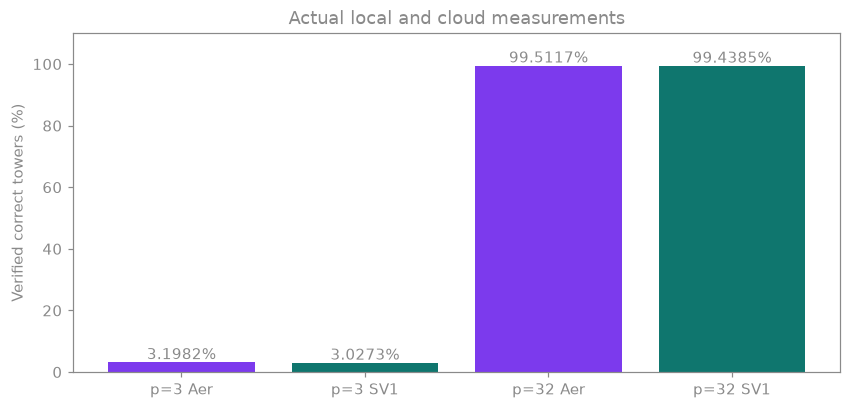

In [13]:
import matplotlib.pyplot as plt
labels = ['p=3 Aer','p=3 SV1','p=32 Aer','p=32 SV1']
rates = [100*local_checks['p3']['success'],100*experiments['p3']['sv1']['verified']['success'],
         100*local_checks['p32']['success'],100*experiments['p32']['sv1']['verified']['success']]
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(labels, rates, color=['#7c3aed','#0f766e','#7c3aed','#0f766e'])
ax.set(ylabel='Verified correct towers (%)', ylim=(0,110), title='Actual local and cloud measurements')
for i,rate in enumerate(rates): ax.text(i,rate+1,f'{rate:.4f}%',ha='center')
plt.show()

## Limits, attribution and AI use

The required uniform-bitstring baseline is **2/4096 = 0.048828%** for the 12 puzzle bits; the original marker is fixed bookkeeping. The stronger uniform-legal-choice baseline is **2/1296 = 0.154321%**, matching the initial legal subspace. The initial p=3 experiment used 13 executed qubits; the final p=32 experiment used 12. Depth includes terminal measurements.

The 32-layer circuit is much deeper. Ideal simulator success does not establish good noisy-hardware performance, a global optimum, or quantum advantage. Four-cube brute force is already fast. Success-focused training uses exact classical simulation; hardware training would need measurement estimates and additional cost.

Puzzle definitions, cost and classical checking functions are adapted from the qBraid challenge starter. `resources/helpers.py` and its package initializer are included unchanged under the challenge's Apache-2.0 license. Codex generated the compact encoding, mixer, optimizers, experiment checks and submission materials. All 4,096 encoding strings were checked, gradients were checked against finite differences, Qiskit independently checked the circuits, and the original checker verified measured towers.

Development errors caught and corrected included side-order differences in a tower comparison, a strict transpilation mismatch in an earlier trial, JSON tuple/list comparison, a NumPy boolean-sign error in gradient code, and console-only datetime serialization after saving results. Only passing final executions support the reported claims. No paid retries were made.

The repository includes only this notebook, the required code/helpers, the seven-slide PDF, dependency list, license, README and three consolidated evidence files. Team names still need to be supplied before final submission.